# Task 2 – Evaluating Reweighing (Kamiran & Calders, 2012)

This notebook evaluates the **Reweighing** pre-processing algorithm on three datasets:
**Adult** (protected attribute: sex), **German Credit** (age) and **COMPAS** (race).

Pipeline per dataset:
1. Load the data and define a binary protected attribute and a binary label (1 = favourable outcome).
2. Compute DP_Diff, DIR and consistency on the **original labels**, before any mitigation or training.
3. Stratified train/test split (70/30), stratified on label and protected group together.
4. Reweighing (AIF360 implementation) on the **training data only**, then train a logistic regression with the instance weights. A baseline logistic regression without weights is trained for reference.
5. On the held-out test data: DP_Diff, DIR, consistency, accuracy and balanced accuracy of the final predictions.
6. Compare the fairness measures before and after mitigation.

Following the paper's assumption that the sensitive attribute is not used at prediction time, the protected attribute is **not** used as a model feature by default. The switch `USE_PROTECTED_AS_FEATURE` in the settings cell lets you run the paper's second scenario, where the classifier may use it.

In [1]:
!pip install aif360 -q

In [2]:
import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger().setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import Reweighing

SEED = 42
TEST_SIZE = 0.3
K_NEIGHBORS = 5
# Paper assumption A2: the sensitive attribute is NOT used for prediction.
# Set to True to also let the classifier see it (the paper's second scenario, Fig. 7).
USE_PROTECTED_AS_FEATURE = False
pd.set_option("display.precision", 4)

## Step 1 – Load the three datasets
Each loader returns a table with the model features, a column `label` (1 = favourable outcome) and a column `prot` (1 = privileged group). The raw files are downloaded directly from UCI and ProPublica.

In [3]:
def load_adult():
    cols = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
            "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
            "hours-per-week", "native-country", "income"]
    base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
    train = pd.read_csv(base + "adult.data", names=cols, skipinitialspace=True, na_values="?")
    test = pd.read_csv(base + "adult.test", names=cols, skipinitialspace=True, na_values="?", skiprows=1)
    df = pd.concat([train, test], ignore_index=True).dropna()
    df["label"] = df["income"].str.replace(".", "", regex=False).eq(">50K").astype(int)
    df["prot"] = (df["sex"] == "Male").astype(int)            # privileged: male
    df = df.drop(columns=["income", "sex", "fnlwgt"])          # fnlwgt dropped as in the paper
    return df


def load_german():
    cols = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings",
            "employment", "installment_rate", "personal_status", "other_debtors", "residence_since",
            "property", "age", "other_installment_plans", "housing", "existing_credits", "job",
            "num_dependents", "telephone", "foreign_worker", "credit"]
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
    df = pd.read_csv(url, sep=" ", names=cols)
    df["label"] = (df["credit"] == 1).astype(int)             # 1 = good credit
    df["prot"] = (df["age"] > 25).astype(int)                 # privileged: older than 25
    df = df.drop(columns=["credit", "age"])
    return df


def load_compas():
    url = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
    raw = pd.read_csv(url)
    # standard ProPublica filtering
    raw = raw[(raw["days_b_screening_arrest"] <= 30) & (raw["days_b_screening_arrest"] >= -30)
              & (raw["is_recid"] != -1) & (raw["c_charge_degree"] != "O") & (raw["score_text"] != "N/A")]
    raw = raw[raw["race"].isin(["African-American", "Caucasian"])]
    df = raw[["sex", "age", "age_cat", "c_charge_degree", "priors_count",
              "juv_fel_count", "juv_misd_count", "juv_other_count"]].copy()
    df["label"] = (raw["two_year_recid"] == 0).astype(int)    # 1 = did not reoffend
    df["prot"] = (raw["race"] == "Caucasian").astype(int)     # privileged: Caucasian
    return df.reset_index(drop=True)


datasets = {"Adult (sex)": load_adult(), "German (age)": load_german(), "COMPAS (race)": load_compas()}
for name, df in datasets.items():
    print(f"{name:15s} rows={len(df):6d}  features={df.shape[1]-2:3d}  "
          f"favourable rate={df['label'].mean():.3f}  privileged share={df['prot'].mean():.3f}")

Adult (sex)     rows= 45222  features= 12  favourable rate=0.248  privileged share=0.675
German (age)    rows=  1000  features= 19  favourable rate=0.700  privileged share=0.810
COMPAS (race)   rows=  5278  features=  8  favourable rate=0.530  privileged share=0.398


## Fairness measures
* **DP_Diff** - Ideal value 0; negative means the unprivileged group gets the favourable outcome less often. (This is the negative of the paper's "discrimination" measure.)
* **DIR** - Ideal value 1; below 0.8 is the common "80% rule" threshold.
* **Consistency** - Ideal value 1; it measures whether similar individuals get similar outcomes. Neighbours are found on the standardised features (protected attribute excluded).

In [4]:
def encode(X_train, X_other=None):
    """One-hot encode categoricals and standardise; fitted on the first table only."""
    Xt = pd.get_dummies(X_train, drop_first=False).astype(float)
    scaler = StandardScaler().fit(Xt)
    out = [scaler.transform(Xt)]
    if X_other is not None:
        Xo = pd.get_dummies(X_other, drop_first=False).astype(float).reindex(columns=Xt.columns, fill_value=0)
        out.append(scaler.transform(Xo))
    return out if X_other is not None else out[0]


def dp_diff(y, prot):
    return y[prot == 0].mean() - y[prot == 1].mean()


def dir_ratio(y, prot):
    return y[prot == 0].mean() / y[prot == 1].mean()


def consistency(X, y, k=K_NEIGHBORS):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(X)
    idx = nn.kneighbors(X, return_distance=False)[:, 1:]       # drop the point itself
    return 1 - np.mean(np.abs(y - y[idx].mean(axis=1)))


def fairness(X, y, prot):
    return {"DP_Diff": dp_diff(y, prot), "DIR": dir_ratio(y, prot), "Consistency": consistency(X, y)}

## Step 2 – Fairness of the original labels (before mitigation, no classifier)

In [5]:
before = {}
for name, df in datasets.items():
    X = encode(df.drop(columns=["label", "prot"]))
    before[name] = fairness(X, df["label"].values, df["prot"].values)
before = pd.DataFrame(before).T
before

,DP_Diff,DIR,Consistency
Adult (sex),-0.1989,0.3635,0.7923
German (age),-0.1494,0.7948,0.6660
COMPAS (race),-0.1323,0.7828,0.6241


## Steps 3–5 – Stratified split, Reweighing, training and test evaluation
The split is stratified on the combination of label and protected group, so all four (group, label) cells keep their proportions in train and test.
Reweighing is fitted on the training set only. As a sanity check, the weighted training data should have DP_Diff approx. 0 and DIR approx. 1, and the AIF360 weights should equal the formula from the paper (expected / observed frequency of each group-label cell).

In [6]:
def run_pipeline(df, seed=SEED, verbose=True):
    X = df.drop(columns=["label", "prot"])
    y, prot = df["label"].values, df["prot"].values
    strata = 2 * y + prot
    X_tr, X_te, y_tr, y_te, p_tr, p_te = train_test_split(
        X, y, prot, test_size=TEST_SIZE, stratify=strata, random_state=seed)
    Xtr, Xte = encode(X_tr, X_te)                              # used for consistency (no S)
    if USE_PROTECTED_AS_FEATURE:
        Mtr, Mte = np.column_stack([Xtr, p_tr]), np.column_stack([Xte, p_te])
    else:
        Mtr, Mte = Xtr, Xte                                    # model features

    # --- Reweighing (AIF360) on the training data only ---
    train_df = pd.DataFrame(Mtr).assign(label=y_tr, prot=p_tr)
    bld = BinaryLabelDataset(df=train_df, label_names=["label"], protected_attribute_names=["prot"],
                             favorable_label=1, unfavorable_label=0)
    rw = Reweighing(unprivileged_groups=[{"prot": 0}], privileged_groups=[{"prot": 1}])
    w = rw.fit_transform(bld).instance_weights

    # check against the paper's formula and that the weighted training data are fair
    n = len(y_tr)
    w_paper = np.array([(p_tr == s).sum() * (y_tr == c).sum() / (n * ((p_tr == s) & (y_tr == c)).sum())
                        for s, c in zip(p_tr, y_tr)])
    assert np.allclose(w, w_paper), "AIF360 weights differ from the paper's formula"
    pos_u = np.sum(w * y_tr * (p_tr == 0)) / np.sum(w * (p_tr == 0))
    pos_p = np.sum(w * y_tr * (p_tr == 1)) / np.sum(w * (p_tr == 1))
    if verbose:
        cells = pd.DataFrame({"group": np.where(p_tr == 1, "privileged", "unprivileged"),
                              "label": np.where(y_tr == 1, "favourable", "unfavourable"), "weight": w})
        print(cells.groupby(["group", "label"])["weight"].first().round(3).to_string())
        print(f"Weighted training data: DP_Diff = {pos_u - pos_p:.4f}, DIR = {pos_u / pos_p:.4f}")

    # --- classifiers ---
    base = LogisticRegression(max_iter=2000).fit(Mtr, y_tr)
    mitigated = LogisticRegression(max_iter=2000).fit(Mtr, y_tr, sample_weight=w)

    res = {}
    for label, model in [("Baseline (no mitigation)", base), ("Reweighing", mitigated)]:
        pred = model.predict(Mte)
        res[label] = {**fairness(Xte, pred, p_te),
                      "Accuracy": accuracy_score(y_te, pred),
                      "Balanced acc.": balanced_accuracy_score(y_te, pred)}
    res["Test labels (reference)"] = fairness(Xte, y_te, p_te)
    return pd.DataFrame(res).T


after = {}
for name, df in datasets.items():
    print(f"\n=== {name} ===")
    after[name] = run_pipeline(df)
    display(after[name])


=== Adult (sex) ===
group         label       
privileged    favourable      0.793
              unfavourable    1.094
unprivileged  favourable      2.183
              unfavourable    0.849
Weighted training data: DP_Diff = 0.0000, DIR = 1.0000


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Baseline (no mitigation),-0.1836,0.3125,0.9264,0.8466,0.7670
Reweighing,-0.0985,0.5667,0.9262,0.8422,0.7529
Test labels (reference),-0.1989,0.3636,0.7809,NaN,NaN



=== German (age) ===
group         label       
privileged    favourable      0.961
              unfavourable    1.105
unprivileged  favourable      1.209
              unfavourable    0.712
Weighted training data: DP_Diff = 0.0000, DIR = 1.0000


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Baseline (no mitigation),-0.0955,0.8828,0.8060,0.8033,0.7198
Reweighing,-0.0563,0.9305,0.7953,0.7933,0.7063
Test labels (reference),-0.1494,0.7948,0.6833,NaN,NaN



=== COMPAS (race) ===
group         label       
privileged    favourable      0.869
              unfavourable    1.204
unprivileged  favourable      1.111
              unfavourable    0.899
Weighted training data: DP_Diff = 0.0000, DIR = 1.0000


,DP_Diff,DIR,Consistency,Accuracy,Balanced acc.
Baseline (no mitigation),-0.2225,0.6830,0.9669,0.6629,0.6595
Reweighing,-0.2152,0.6962,0.9650,0.6635,0.6595
Test labels (reference),-0.1322,0.7828,0.6111,NaN,NaN


## Step 6 – Comparison before vs. after mitigation
"Original labels" is the Step 2 result on the full dataset; the two other rows are the classifier predictions on the held-out test set.

In [7]:
rows = []
for name in datasets:
    rows.append({"Dataset": name, "Stage": "Original labels", **before.loc[name].to_dict()})
    for stage in ["Baseline (no mitigation)", "Reweighing"]:
        rows.append({"Dataset": name, "Stage": stage, **after[name].loc[stage].to_dict()})
comparison = pd.DataFrame(rows).set_index(["Dataset", "Stage"])
comparison

DP_Diff     DIR  Consistency  \
Dataset       Stage                                                    
Adult (sex)   Original labels           -0.1989  0.3635       0.7923   
              Baseline (no mitigation)  -0.1836  0.3125       0.9264   
              Reweighing                -0.0985  0.5667       0.9262   
German (age)  Original labels           -0.1494  0.7948       0.6660   
              Baseline (no mitigation)  -0.0955  0.8828       0.8060   
              Reweighing                -0.0563  0.9305       0.7953   
COMPAS (race) Original labels           -0.1323  0.7828       0.6241   
              Baseline (no mitigation)  -0.2225  0.6830       0.9669   
              Reweighing                -0.2152  0.6962       0.9650   

                                        Accuracy  Balanced acc.  
Dataset       Stage                                              
Adult (sex)   Original labels                NaN            NaN  
              Baseline (no mitigation)    0.8466         0.7670  
              Reweighing                  0.8422         0.7529  
German (age)  Original labels                NaN            NaN  
              Baseline (no mitigation)    0.8033         0.7198  
              Reweighing                  0.7933         0.7063  
COMPAS (race) Original labels                NaN            NaN  
              Baseline (no mitigation)    0.6629         0.6595  
              Reweighing                  0.6635         0.6595

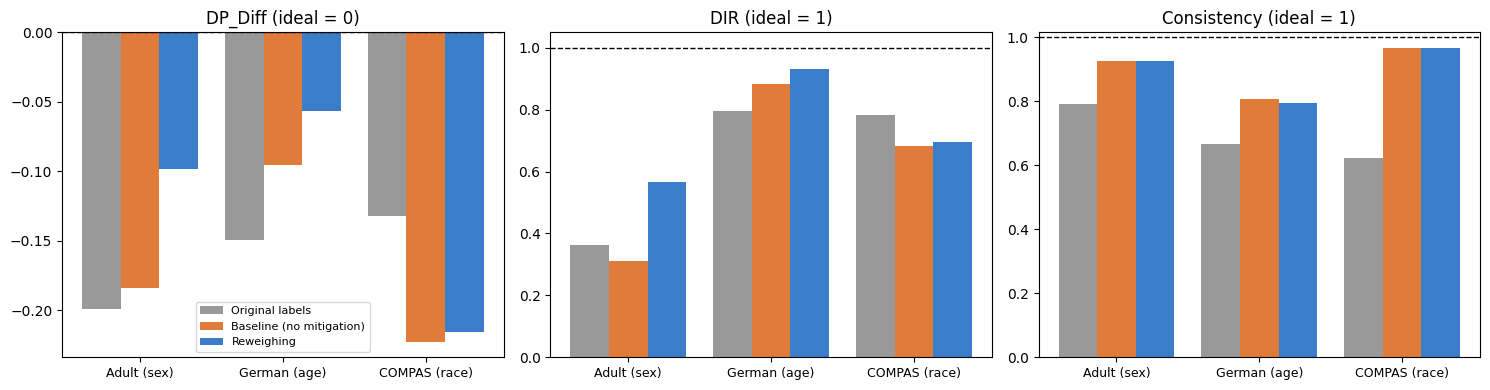

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
stages = ["Original labels", "Baseline (no mitigation)", "Reweighing"]
colors = ["#999999", "#e07b39", "#3a7dc9"]
for ax, metric, ideal in zip(axes, ["DP_Diff", "DIR", "Consistency"], [0, 1, 1]):
    x = np.arange(len(datasets))
    for i, (stage, c) in enumerate(zip(stages, colors)):
        vals = [comparison.loc[(d, stage), metric] for d in datasets]
        ax.bar(x + (i - 1) * 0.27, vals, width=0.27, label=stage, color=c)
    ax.axhline(ideal, color="black", lw=1, ls="--")
    ax.set_xticks(x)
    ax.set_xticklabels(list(datasets), fontsize=9)
    ax.set_title(f"{metric} (ideal = {ideal})")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Extra – Robustness over 10 random splits
A single split can be noisy, especially for the small German dataset (1,000 rows). This repeats Steps 3–5 for 10 seeds and reports mean plus/minus standard deviation.

In [9]:
summary = {}
for name, df in datasets.items():
    runs = pd.concat([run_pipeline(df, seed=s, verbose=False).assign(seed=s) for s in range(10)])
    runs = runs.drop(index="Test labels (reference)").drop(columns="seed")
    g = runs.groupby(level=0)
    summary[name] = g.mean().round(4).astype(str) + " ± " + g.std().round(4).astype(str)
pd.concat(summary)

DP_Diff              DIR  \
Adult (sex)   Baseline (no mitigation)  -0.1806 ± 0.0057  0.3124 ± 0.0136   
              Reweighing                -0.0983 ± 0.0066  0.5602 ± 0.0212   
German (age)  Baseline (no mitigation)  -0.1197 ± 0.0363  0.8456 ± 0.0468   
              Reweighing                -0.0731 ± 0.0367   0.9053 ± 0.047   
COMPAS (race) Baseline (no mitigation)   -0.249 ± 0.0133  0.6564 ± 0.0182   
              Reweighing                -0.2476 ± 0.0116  0.6634 ± 0.0182   

                                            Consistency         Accuracy  \
Adult (sex)   Baseline (no mitigation)  0.9246 ± 0.0021  0.8448 ± 0.0017   
              Reweighing                0.9264 ± 0.0019  0.8404 ± 0.0026   
German (age)  Baseline (no mitigation)  0.7652 ± 0.0157   0.756 ± 0.0197   
              Reweighing                 0.7667 ± 0.016   0.753 ± 0.0223   
COMPAS (race) Baseline (no mitigation)  0.9661 ± 0.0041  0.6729 ± 0.0068   
              Reweighing                0.9642 ± 0.0049   0.674 ± 0.0086   

                                          Balanced acc.  
Adult (sex)   Baseline (no mitigation)  0.7621 ± 0.0042  
              Reweighing                0.7478 ± 0.0053  
German (age)  Baseline (no mitigation)  0.6851 ± 0.0291  
              Reweighing                0.6794 ± 0.0324  
COMPAS (race) Baseline (no mitigation)  0.6691 ± 0.0065  
              Reweighing                0.6695 ± 0.0083